# A fold-transversal logical Hadamard, verified with syndrome measurement

**In short.** A quantum computer protects a qubit by spreading it over many physical qubits, a *code*. Here the code is the distance-3 surface code: nine *data qubits* in a 3×3 grid, checked again and again by eight *helper qubits*. A *logical Hadamard* is the Hadamard gate applied to the protected qubit as a whole. This protocol does it without ever unprotecting the qubit: an H on every data qubit turns the code into its mirror image (the *dual* code), and rotating the grid by 90° turns the mirror image back, with rounds of checks in between.

The tool is given nothing but the gates. It answers at three levels, and the pictures follow them:

| level | what you see | section |
|---|---|---|
| 1. the physical circuit | 19 qubits, 8 stages, 34 measurements, drawn on a time axis and in 3D | 1 |
| 2. the blocks | each stage drawn step by step on the qubit grid; for each block, the code before and after and what it does to the protected qubit | 2 |
| 3. the logical operation | the whole protocol is a **Hadamard on the protected qubit in every run**, followed by a correction the measurement results determine | 3 |

New to error correction or ZX-diagrams? Part A of `TInjectionWalkthrough.ipynb` explains qubits, codes, checks and the pictures in a few minutes.

**In more detail.** Every measurement outcome is kept **symbolic** (Boolean variables `c[i]`), and the diagram is reduced with the generalized parity form with phases (`zxqec.gpf`):

* the protocol reduces to a Hadamard **plus an outcome-dependent Pauli frame**, the corrections a decoder would apply;
* the reduction also produces the **detectors**: the parities of outcomes that are always 0 in the noiseless circuit;
* setting all outcomes to 0 leaves exactly a Hadamard.

The protocol: encode the logical qubit and run an X-check round (code 1); apply a transversal Hadamard, which moves the information to the dual code; run a QEC round of code 2; rotate the data grid by 90°, which maps the dual code's boundaries back onto the original layout; run QEC rounds of code 1 and decode. The circuit files are in `circuits/ft_h/` (see the README there for the qubit roles).

In [1]:
%matplotlib inline
import os, random, time
import pyzx as zx
from pyzx.circuit import Circuit
from pyzx.circuit.gates import HAD, Reset
from pyzx.utils import VertexType
from zxqec.qprogram import QProgram
from zxqec.spacetime import Topology, draw_graph, draw_program, draw_program_3d, draw_program_slices
from zxqec.gpf import reduce_gpf, boolean_variables, detector_rank, has_boundary_hadamard, is_gpf, sample_consistent_assignment

N, BITS = 19, 35
X_ANC, Z_ANC = [10, 11, 12, 13], [14, 15, 16, 17]

def load(name):
    return zx.Circuit.load(os.path.join("circuits", "ft_h", name + ".qasm"))

def with_prefix(circ, gates):
    """``gates`` (ancilla preparations) followed by ``circ``."""
    c = Circuit(N, bit_amount=BITS)
    for g in gates:
        c.add_gate(g)
    c.add_circuit(circ)
    return c

## 1. Level 1: the physical circuit

The protocol is given as eight stages of gates on 19 qubits: the nine data qubits 1–9 in a 3×3 grid, the eight helper qubits 10–17 that measure the checks, the input qubit 0 and the output qubit 18. The first stage *encodes* the input into the code and the last stage *decodes* it back onto qubit 18, so the circuit starts and ends with one unprotected qubit.

Data qubits and the decode ancilla start in $|0\rangle$, the check ancillas in $|+\rangle$; the logical input `q[0]` stays open. The circuit files reuse ancillas after measuring them without re-preparing them, so a `reset` (and an `h` for the X checks) is added at the start of the stages that reuse them. The stages after the rotation are written in the **physical frame** — "qubit 1" means the position in the grid — which `add_circuit(..., physical=True)` translates into the logical qubits currently sitting there.

In [2]:
p = QProgram(N, bits=BITS,
             initial_states={**{q: '0' for q in range(1, 10)}, 18: '0', **{a: '+' for a in X_ANC + Z_ANC}})
p.add_circuit(load("ft_h"), name="encode + X checks")
p.add_circuit(load("ft_h_2"), name="transversal H")
p.add_circuit(with_prefix(load("ft_h_3"), [Reset(a) for a in X_ANC]), name="Z checks (code 2)")
p.add_circuit(load("ft_h_3.2"), name="X checks (code 2)")
p.add_permutation([0, 3, 6, 9, 2, 5, 8, 1, 4, 7] + list(range(10, 19)), name="rotate 90°")
p.add_circuit(with_prefix(load("ft_h_5"), [Reset(a) for a in Z_ANC]), name="Z checks", physical=True)
p.add_circuit(with_prefix(load("ft_h_5.2"), [g for a in X_ANC for g in (Reset(a), HAD(a))]), name="X checks", physical=True)
p.add_circuit(with_prefix(load("ft_h_6"), [Reset(a) for a in Z_ANC]), name="Z checks + decode", physical=True)

g = p.quantum_graph()          # the master graph without the (inert) classical-bit wires
print(sum(1 for v in g.vertices() if g.type(v) != VertexType.BOUNDARY), "spiders;",
      "inputs", g.inputs(), "outputs", g.outputs())
print(len(boolean_variables(g)), "measurement outcomes as Boolean variables")
print(p.describe_level(0))

311 spiders; inputs (0,) outputs (347,)
34 measurement outcomes as Boolean variables
Level 0 (8 blocks):
  Block 0 'encode + X checks': [encode + X checks]
  Block 1 'transversal H': [transversal H]
  Block 2 'Z checks (code 2)': [Z checks (code 2)]
  Block 3 'X checks (code 2)': [X checks (code 2)]
  Block 4 'rotate 90°': [rotate 90°]
  Block 5 'Z checks': [Z checks]
  Block 6 'X checks': [X checks]
  Block 7 'Z checks + decode': [Z checks + decode]


The whole protocol on a time axis. Time runs from left to right, each horizontal line is a qubit, and the green and red dots are the gates (ZX-spiders; a CNOT is a green dot on its control joined to a red dot on its target). The shaded bands are the eight stages, from the encoder on the left to the decoder on the right; the rotation is the narrow stage in the middle where the data wires cross:

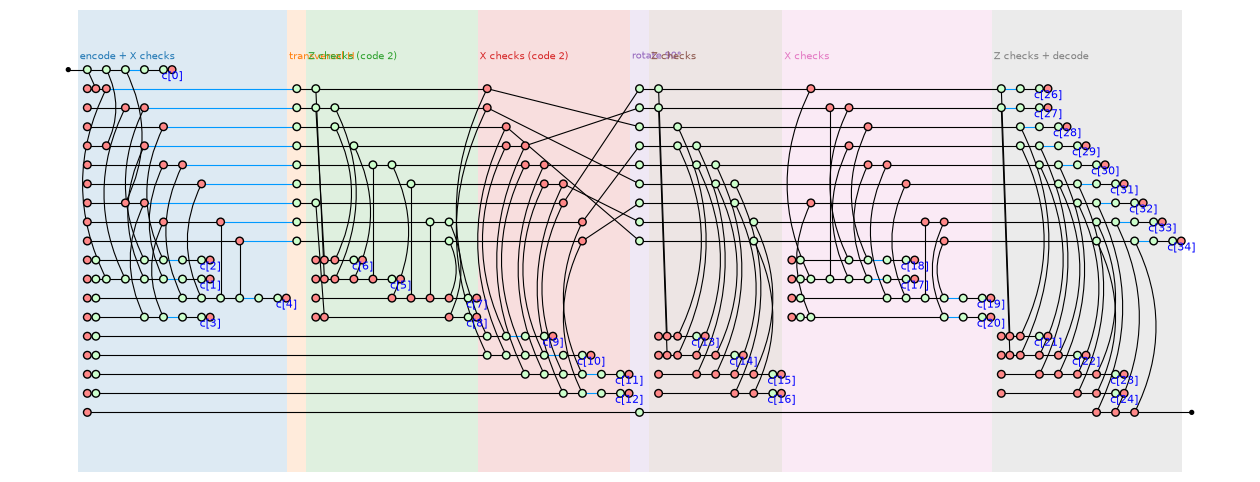

In [3]:
draw_program(p, level=0, show_time=False, labels=False, figsize=(16, 6))      # timestep labels off: too dense for 300 spiders

The same on the layout of the 19 qubits (the 3×3 data grid with the check ancillas between the plaquettes), time upwards, one slab per stage:

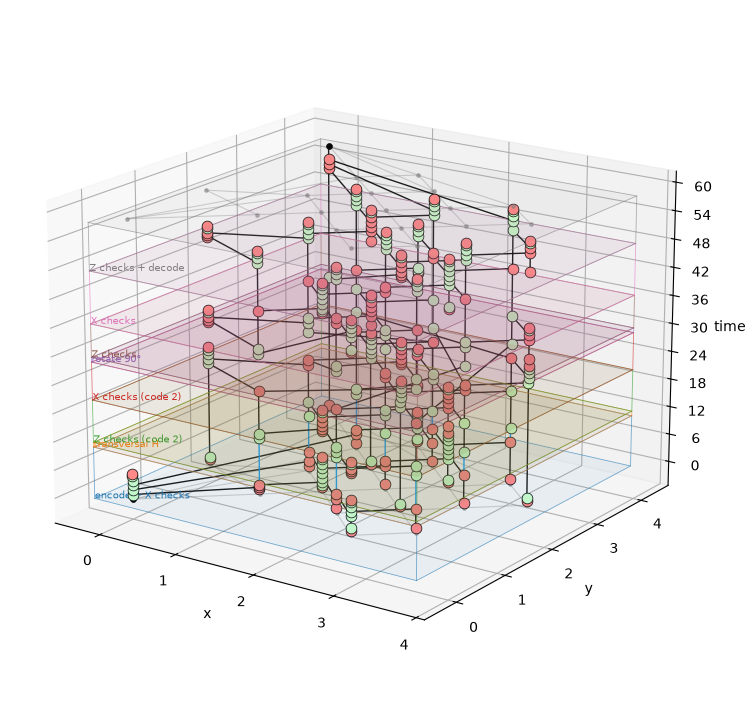

In [4]:
coords = {0: (0, 0), 1: (1, 1), 2: (2, 1), 3: (3, 1), 4: (1, 2), 5: (2, 2), 6: (3, 2), 7: (1, 3), 8: (2, 3), 9: (3, 3),
          10: (2.5, 0.5), 11: (1.5, 1.5), 12: (2.5, 2.5), 13: (1.5, 3.5), 14: (0, 1.5), 15: (2.5, 1.5), 16: (1.5, 2.5), 17: (3.5, 2.5), 18: (0, 4)}
topo = Topology(2)
for n, c in coords.items():
    topo.add_node(n, c)
for a, b in [(1, 11), (2, 11), (4, 11), (5, 11), (2, 10), (3, 10), (5, 12), (6, 12), (8, 12), (9, 12), (7, 13), (8, 13),
             (1, 14), (4, 14), (2, 15), (3, 15), (5, 15), (6, 15), (4, 16), (5, 16), (7, 16), (8, 16), (6, 17), (9, 17),
             (0, 1), (0, 4), (0, 7), (7, 18), (8, 18), (9, 18)]:
    topo.add_edge(a, b)
p.topology = topo
draw_program_3d(p, level=0, figsize=(10, 9), show_phases=False, elev=18, azim=-55)

## 2. Level 2: the blocks, and each stage step by step

The tool groups the stages into six blocks, and for each says which code the qubits are in before and after, and what the block does to the protected qubit:

block               role                 code before  code after  logical action  every run?  checks
0 encode + round 1  encoder              [[1,1,1]]    [[9,1,3]]   I               yes         ok
1 transversal H     logical gate         [[9,1,3]]    [[9,1,3]]   H               yes         ok
2 round in code 2   syndrome extraction  [[9,1,3]]    [[9,1,3]]   I               yes         ok
3 rotate            logical gate         [[9,1,3]]    [[9,1,3]]   I               yes         ok
4 round in code 1   syndrome extraction  [[9,1,3]]    [[9,1,3]]   I               yes         ok
5 checks + decode   decoder              [[9,1,3]]    [[1,1,1]]   I               yes         ok


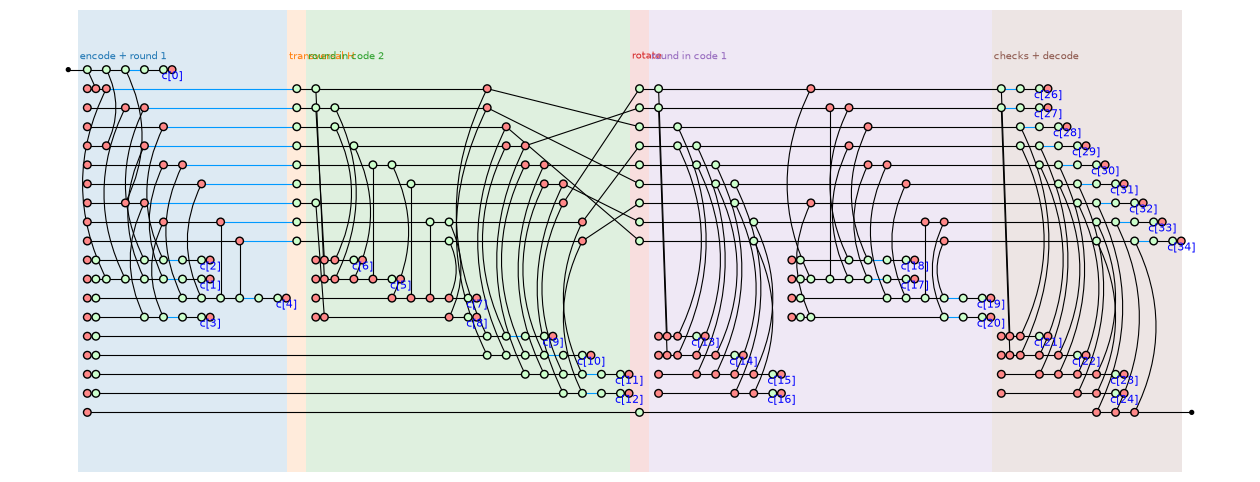

In [5]:
groups = [(0, 0, 'encode + round 1', 'encoder'), (1, 1, 'transversal H', 'logical gate'),
          (2, 3, 'round in code 2', 'syndrome extraction'), (4, 4, 'rotate', 'logical gate'),
          (5, 6, 'round in code 1', 'syndrome extraction'), (7, 7, 'checks + decode', 'decoder')]
blocks = p.group_stages(groups)
print(p.summary(blocks).table())
draw_program(p, level=blocks, show_time=False, labels=False, figsize=(16, 6))

Reading the table: `[[9,1,3]]` is the surface code (nine qubits, one protected qubit, distance 3: any single error can be found and fixed), `[[1,1,1]]` a single bare qubit. *Logical action* is what the block does to the protected qubit. Only the transversal H does anything (it is a logical **H**); the encoder, the rounds of checks, the rotation and the decoder leave the protected qubit as it is (**I**). *Every run?* says that this holds whatever the measurements return.

### Each stage, one time step at a time

Below, each stage is cut into its time steps, and each step is drawn on the qubit grid, as seen from above (`draw_program_slices`): a dot is a gate acting at that moment, a line joins the two qubits of a CNOT, and a label `c[i]` marks a measurement. The faint lines are the hardware connections.

**Stage 0, the encoder.** The input qubit 0 is copied onto data qubits 1, 4 and 7 with CNOTs and then measured in the X basis (`c[0]`), which leaves its state in the code; the four X checks are measured with the helpers 10–13 (`c[1]`–`c[4]`).

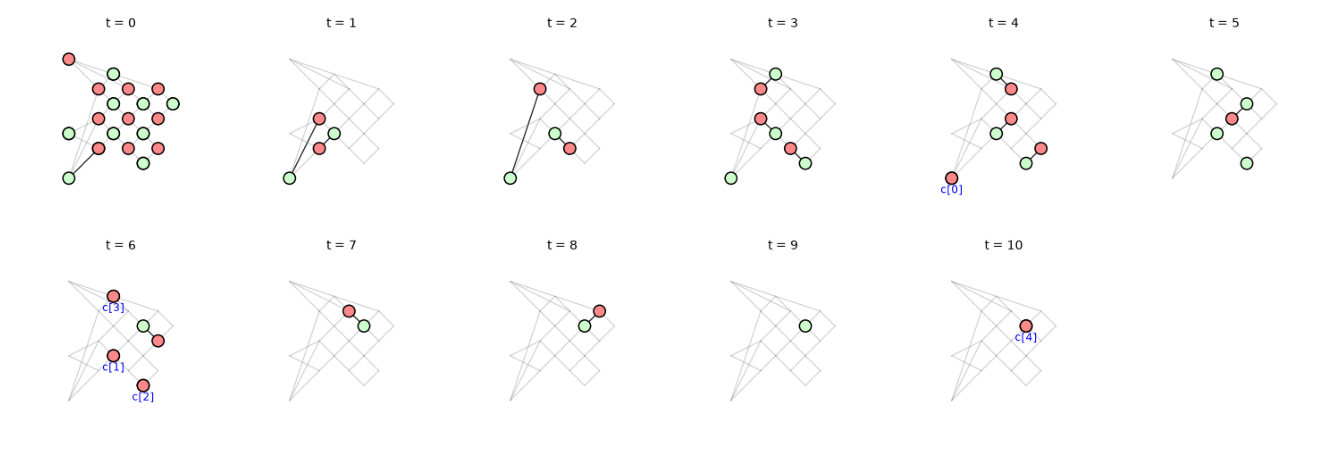

In [6]:
draw_program_slices(p, stage=0, cols=6, panel=(2.2, 2.2))

**Stage 1, the transversal H.** One H on each of the nine data qubits, all at the same time step. This turns the code into its dual: the X checks become Z checks and the other way round.

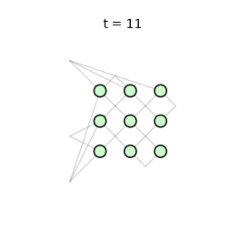

In [7]:
draw_program_slices(p, stage=1, cols=6, panel=(2.2, 2.2))

**Stage 2, the Z checks of the dual code.** Each helper 10–13 collects the parity of its data qubits with CNOTs and is measured (`c[5]`–`c[8]`).

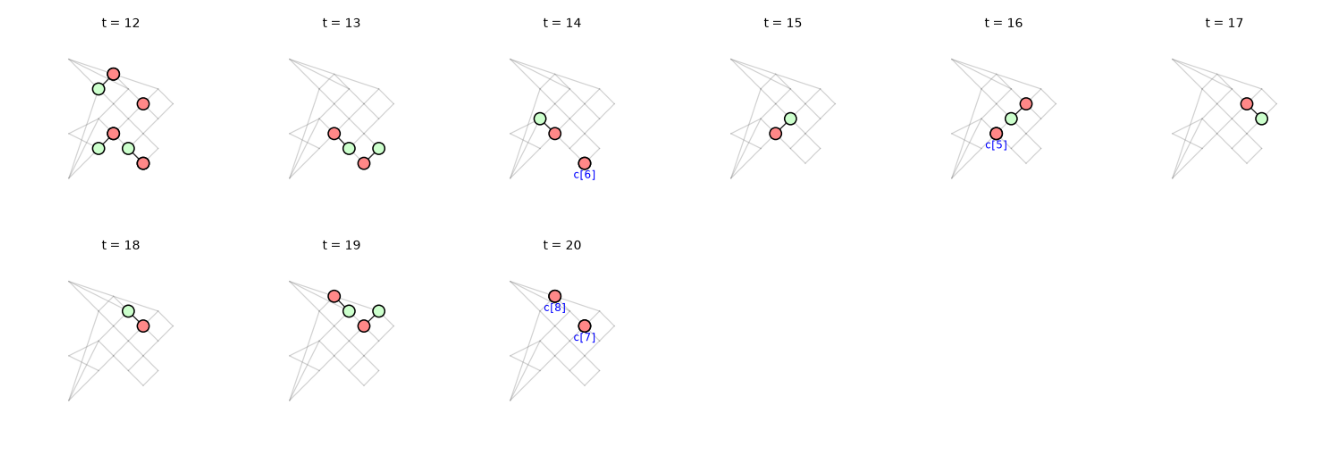

In [8]:
draw_program_slices(p, stage=2, cols=6, panel=(2.2, 2.2))

**Stage 3, the X checks of the dual code**, measured with the helpers 14–17 (`c[9]`–`c[12]`).

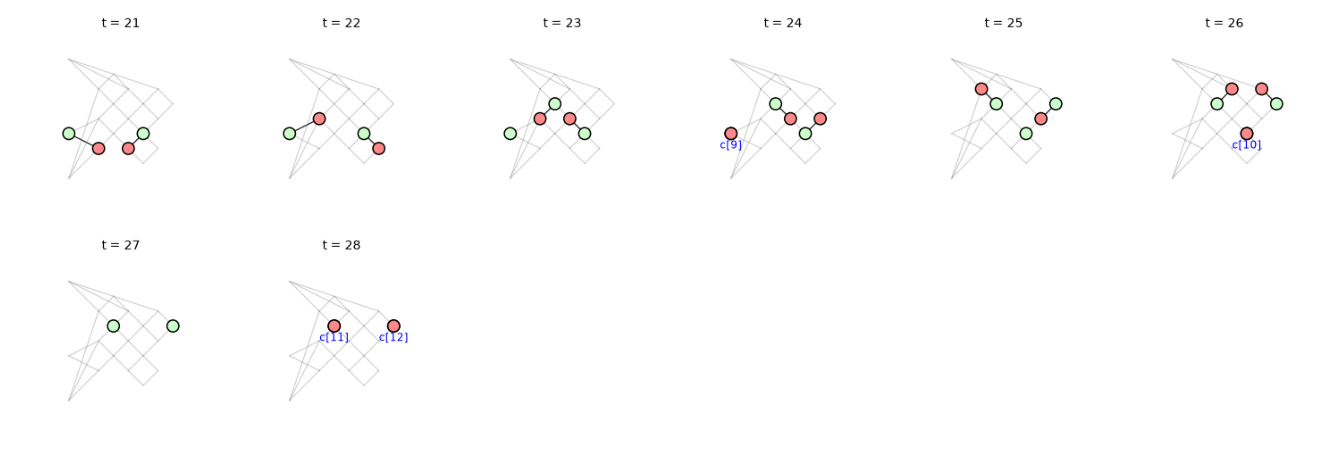

In [9]:
draw_program_slices(p, stage=3, cols=6, panel=(2.2, 2.2))

**Stage 4, the rotation.** No gates: the data qubits move to the positions of the grid rotated by 90°, which maps the dual code back onto the original layout. Drawn on a time axis, the wires cross:

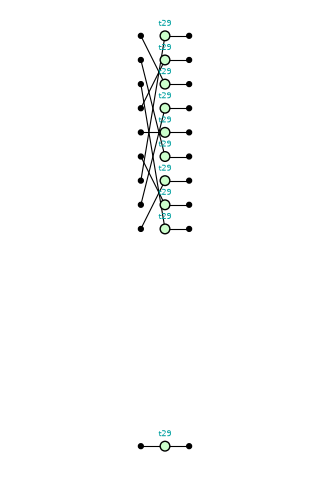

In [10]:
draw_graph(p.stage_graph(4, classical=False), show_time=False, figsize=(5, 6))

**Stage 5, the Z checks of the original code**, with the helpers 14–17 (`c[13]`–`c[16]`).

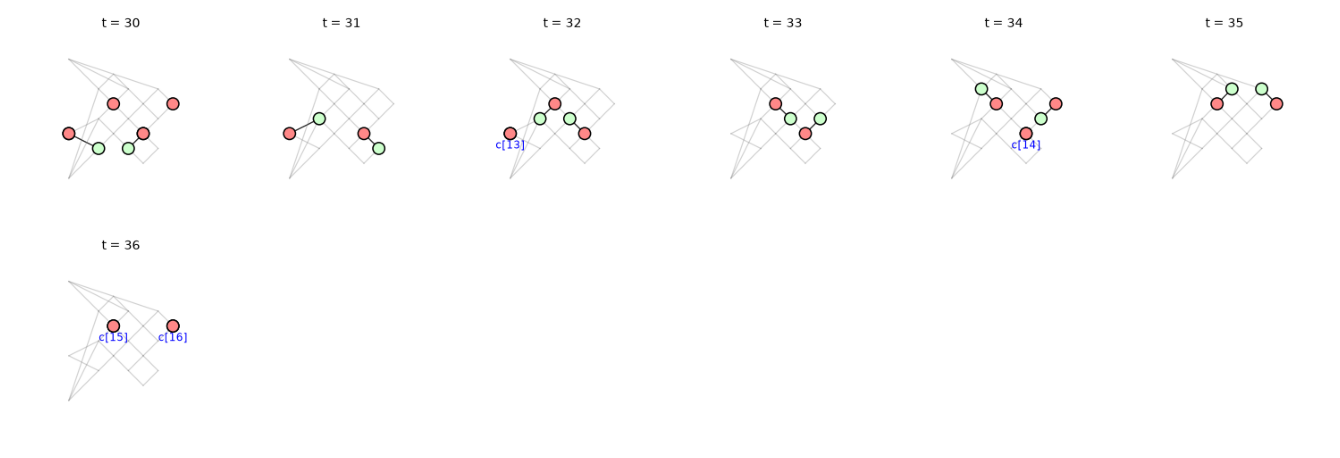

In [11]:
draw_program_slices(p, stage=5, cols=6, panel=(2.2, 2.2))

**Stage 6, the X checks**, with the helpers 10–13 (`c[17]`–`c[20]`).

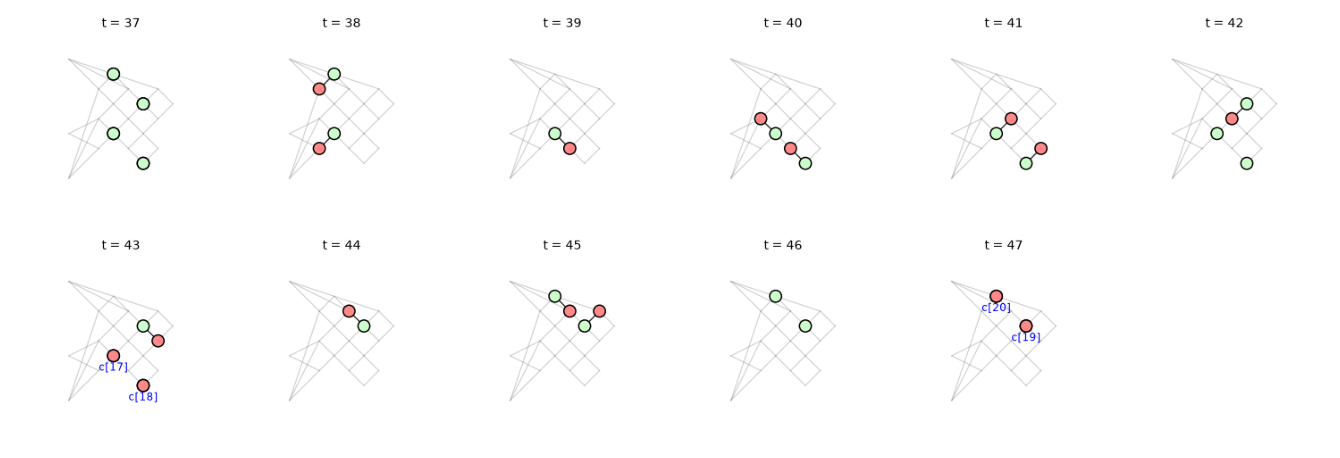

In [12]:
draw_program_slices(p, stage=6, cols=6, panel=(2.2, 2.2))

**Stage 7, the decoder.** A last round of Z checks (`c[21]`–`c[24]`); the protected qubit is copied out onto qubit 18 with CNOTs from data qubits 3, 6 and 9, and the nine data qubits are measured in the X basis (`c[26]`–`c[34]`).

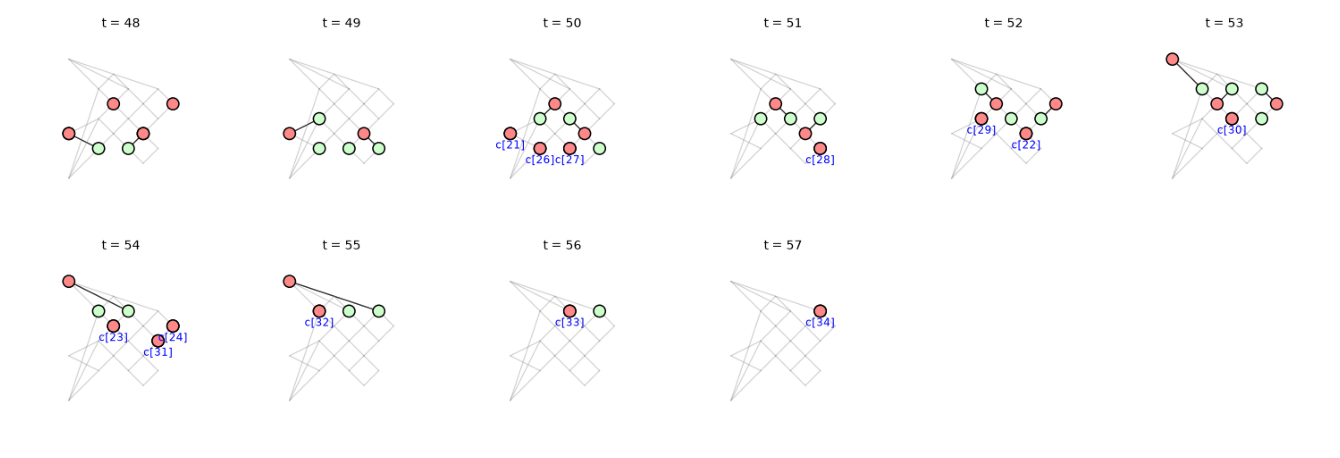

In [13]:
draw_program_slices(p, stage=7, cols=6, panel=(2.2, 2.2))

## 3. Level 3: the logical Hadamard

One block for the whole protocol. The tool's verdict:

In [14]:
whole = p.level_up(blocks, 0, len(groups) - 1, name='whole program', role='logical gate')
print(p.summary(whole))

block            role          code before  code after  logical action  every run?  checks
0 whole program  logical gate  [[1,1,1]]    [[1,1,1]]   H               yes         ok

Block 0 'whole program' (logical gate) -- stages 0, 1, 2, 3, 4, 5, 6, 7
  code before: [[1,1,1]] on qubits 0
  code after:  [[1,1,1]] on qubits 18
  logical action: deterministic up to a Pauli frame: every run implements H followed by a Pauli correction (X, Y, Z, none) that the outcomes determine
  measurements: 34 (8 fixed, 8 frame, 18 tied)
  ok      implements H in every run


How the tool gets there: `reduce_gpf` brings the 300-spider master graph into a bipartite Z/X form and row-reduces both layers over GF(2), carrying the outcome-dependent Pauli phases along. A row that empties out is the scalar $1 + (-1)^p$, which forces $p = 0$: a **detector**. What is left is the picture below: the input, an H on its wire, one green and one red spider carrying the correction, and the output.

reduced in 0.02s; GPF shape: True; zero diagram: False
  BOUNDARY phase = 0 (Hadamard on this wire)
  X        phase = c[4] + c[0] + c[3] + c[1] + c[2]
  BOUNDARY phase = 0
  Z        phase = c[29] + c[26] + c[32]


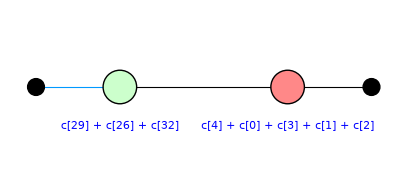

In [15]:
t0 = time.time()
res = reduce_gpf(g, isolate_paulis = False)
r = res.graph
print(f"reduced in {time.time() - t0:.2f}s; GPF shape: {is_gpf(r)}; zero diagram: {res.is_zero}")
for v in sorted(r.vertices()):
    tag = " (Hadamard on this wire)" if r.type(v) == VertexType.BOUNDARY and has_boundary_hadamard(r, v) else ""
    print(f"  {VertexType(r.type(v)).name:<8} phase = {r.phase(v)}{tag}")
zx.draw_matplotlib(res.to_graph(), figsize=(5, 2))

The logical operation is a Hadamard followed by an outcome-dependent **Pauli frame**. The Hadamard sits on the *input* wire — `push_hadamards_to_boundary` puts boundary Hadamards on inputs where it can — so the diagram is read in the order a decoder acts: apply $H$, then correct the output with $Z^b$ and $X^a$, where $b = c_{26}+c_{29}+c_{32}$ is the X-basis readout of one column of the data grid (the logical X operator) and $a = c_0+c_1+c_2+c_3+c_4$ is the injection outcome together with the first X-check round, whose outcomes are random because the fan-out state is not an eigenstate of those checks. These are exactly the corrections a decoder applies in the noiseless case. Only 8 of the 34 outcomes appear in the diagram, and only through these two parities; §4 says what happens to each of the others.

The detectors:

In [16]:
for c in res.constraints:
    print("  ", c, "= 0")
print(len(res.constraints), "detectors")

   c[5] + c[1] = 0
   c[6] + c[2] = 0
   c[8] + c[3] = 0
   c[7] + c[4] = 0
   c[9] = 0
   c[11] = 0
   c[10] = 0
   c[16] + c[2] = 0
   c[14] + c[1] = 0
   c[12] = 0
   c[13] + c[3] = 0
   c[15] + c[4] = 0
   c[17] = 0
   c[18] = 0
   c[21] + c[3] = 0
   c[22] + c[1] = 0
   c[28] + c[27] = 0
   c[30] + c[27] + c[29] + c[26] = 0
   c[19] = 0
   c[20] = 0
   c[24] + c[2] = 0
   c[23] + c[4] = 0
   c[33] + c[32] = 0
   c[34] + c[31] + c[27] + c[29] + c[26] + c[32] = 0
24 detectors


Reading them: `c[9]`–`c[12]` and `c[17]`–`c[20]` are checks whose outcome is deterministic on the prepared state; `c[6]+c[2]`, `c[5]+c[1]`, … say that a check repeated in a later round (after the transversal Hadamard, or after the rotation) must give the same outcome as the first X-check round; the last four are X stabilizers read off the final data measurements.

**A wiring error found by the symbolic analysis.** An earlier version of these circuit files had one Z check wired to the wrong qubit. On it, this reduction gave 22 detectors and two anomalies:

* `c[13]`, an ancilla check in the middle of the protocol (q14, stage 5), appeared in no detector and in no phase — a random outcome that is never re-checked and affects nothing. In a correct noiseless protocol that cannot happen: every mid-circuit check measures a stabilizer, so its outcome is either deterministic or equal to the value the same operator had when it was last measured.
* `c[18]`, the X check on positions 2 and 3, was random and in the Pauli frame, while its three siblings in the same round were deterministic 0. An X check can only turn random if something anticommuting with it was measured in between.

The only measurements in between are the stage-5 Z checks, and a genuine CSS Z stabilizer commutes with every X stabilizer — so one of them was not a stabilizer, and the first anomaly named its ancilla. The file confirms it: `ft_h_5.qasm` wired q14 to positions 1 and 2, i.e. $Z_1Z_2$ (odd overlap with $X_2X_3$, as predicted), where every other stage wires it to positions 1 and 4. Changing that one character gives 24 detectors, `c[13] = c[3]`, `c[18] = 0`, and every outcome accounted for.

Post-selection cannot see this: $Z_1Z_2$ lies outside the normalizer of the stabilizer group, so a logical representative commuting with it exists ($X_L \cdot X_2X_3$), the logical information survives, and the protocol still gives `H` — it just accepts a quarter as often. What the bad check damages is the code, not the map: it randomises one stabilizer and costs two detectors. The file is corrected here (see `circuits/ft_h/README.md`).

### Where the other 26 variables went

No rewrite rule removes a variable: fusion adds phases mod 2, the Boolean bialgebra rule copies them, and a row addition is a change of summation variable that adds the phases too. A variable can only leave the graph when a spider is left with no edges: an isolated spider $Z(\pi p)$ or $X(\pi p)$ is the scalar $1 + e^{i\pi p} = 1 + (-1)^p$, which PyZX's `remove_isolated_vertices` records in `g.scalar` — that factor is $2$ when $p = 0$ and $0$ when $p = 1$, i.e. exactly a detector. The full statement is therefore

$$D(c) \;=\; \lambda(c)\,\prod_{k=1}^{24}\bigl(1 + (-1)^{p_k(c)}\bigr)\, D_{\mathrm{red}}(c), \qquad \lambda(c) \neq 0 .$$

`TrackingOutcomeVariables.ipynb` follows individual variables through every rewrite of both pipelines and shows this happening. The quickest independent check here is that PyZX's own simplifier, which never applies the Boolean bialgebra rule, accumulates the same factors in its scalar:

In [17]:
fr = g.copy(); zx.full_reduce(fr)                      # PyZX's simplifier on the symbolic master graph
pz = list(fr.scalar.phasenodes)                        # every factor 1 + e^{i pi p} it met
print(f"full_reduce leaves {sum(1 for v in fr.vertices() if fr.type(v) != VertexType.BOUNDARY)} spiders "
      f"and {len(pz)} phase nodes in g.scalar")
print("same GF(2) span as our detectors:",
      detector_rank(pz) == detector_rank(res.detectors) == detector_rank(pz + list(res.detectors)))

full_reduce leaves 18 spiders and 24 phase nodes in g.scalar
same GF(2) span as our detectors: True


### Every phase as a gadget

`isolate_paulis=True` unfuses *every* non-zero phase into a gadget, the Pauli ones included. With symbolic outcomes each of the 34 `X(π c[i])` spiders becomes a leaf whose stem anchors its row, so the row reduction may not eliminate anything next to a measurement. The result is a correct diagram but not a reduced one — 96 vertices and no detectors — and since the sanity checks of section 5 draw their outcomes from the detectors, they cannot be run on it. Keeping the Pauli phases on the spiders is what turns this into `H` + Pauli frame + 24 detectors. (On the all-zero, phase-free diagram both modes give the same 4-vertex result.)


                                vertices  detectors
phases stay on spiders                 4         24
isolate_paulis=True                   96          0
on a possible outcome the all-gadget diagram still agrees with full_reduce(master): True


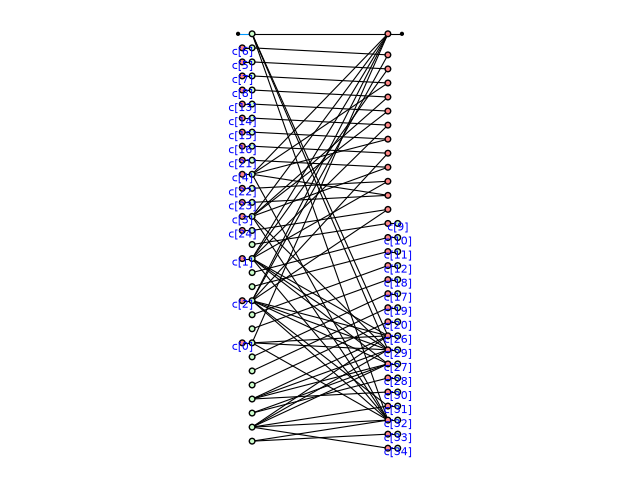

In [18]:
res_gadgets = reduce_gpf(g, isolate_paulis=True)      # every non-zero phase becomes a gadget
print(f"{'':30}{'vertices':>10}{'detectors':>11}")
print(f"{'phases stay on spiders':30}{res.graph.num_vertices():>10}{len(res.detectors):>11}")
print(f"{'isolate_paulis=True':30}{res_gadgets.graph.num_vertices():>10}{len(res_gadgets.detectors):>11}")
a = sample_consistent_assignment(res.constraints, boolean_variables(g), random.Random(0))   # a possible outcome, from the detectors above
ga = g.substitute_variables(a); zx.full_reduce(ga)
print("on a possible outcome the all-gadget diagram still agrees with full_reduce(master):",
      zx.compare_tensors(ga, res_gadgets.to_graph().substitute_variables(a), preserve_scalar=False))
zx.draw_matplotlib(res_gadgets.to_graph(), figsize=(8, 6))


## 4. The measurement report

`p.measurement_report()` turns the reduction into the table a user of the protocol wants: for each measurement, where it was taken and what happens to it in the error-free setting — the map depends on it (**frame**), a detector fixes its value (**fixed**), the detectors tie it to other outcomes (**tied**), or nothing constrains it and nothing depends on it (**gauge**).

In [19]:
rep = p.measurement_report()
print(rep.summary())
print()
print(rep.table())

34 measurements in the whole diagram; Pauli frame: Z(c[29] + c[26] + c[32]), X(c[4] + c[0] + c[3] + c[1] + c[2])
8 frame; 8 fixed; 18 tied
24 detectors (24 of them internal); outcome space of the diagram: 24 forced + 2 steering the map + 8 gauge = 34

outcome  stage  qubit  pos  t   fate   why
c[0]     0      0      0    4   frame  the map depends on it: X correction, with c[1], c[2], c[3], c[4]
c[1]     0      11     11   6   frame  the map depends on it: X correction, with c[0], c[2], c[3], c[4]
c[2]     0      10     10   6   frame  the map depends on it: X correction, with c[0], c[1], c[3], c[4]
c[3]     0      13     13   6   frame  the map depends on it: X correction, with c[0], c[1], c[2], c[4]
c[4]     0      12     12   10  frame  the map depends on it: X correction, with c[0], c[1], c[2], c[3]
c[6]     2      10     10   14  tied   its parity with c[2] (stage 0, qubit 10, t=6) is deterministic (c[6] + c[2] = 0)
c[5]     2      11     11   16  tied   its parity with c[1] (stag

Reading the columns: `qubit` is the logical qubit, `pos` the physical position it sat on — they differ after the rotation (`c[28]` is logical qubit 1 at position 3). The `why` column phrases each fate in terms of the protocol's own measurements.

Two cautions about the counting in the summary line. It is in **dimensions** of the outcome space, not in variable names: `24 forced + 2 steering the map + 8 gauge = 34`. The Pauli frame mentions eight names but is only two independent parities — flipping `c[26]` and `c[29]` together does not change the map. And *gauge* is a direction, not a name: in this protocol every variable appears in some detector or in the frame, yet 8 of the 10 free dimensions have no effect on the map.

Given the outcomes of a run it answers the decoder's two questions: which detectors fired, and which Pauli correction to apply.

In [20]:
shot = {n: 0 for n in rep.measurements}                  # an all-zero run
print("all-zero run  : violated", rep.violated(shot), " frame", rep.frame_values(shot), " possible", rep.is_possible(shot))
shot = dict(shot, **{'c[1]': 1, 'c[5]': 1, 'c[14]': 1, 'c[22]': 1})    # a consistent random run
print("consistent run: violated", rep.violated(shot), " frame", rep.frame_values(shot), " possible", rep.is_possible(shot))
shot = dict(shot, **{'c[9]': 1})                          # a deterministic check came out 1
print("faulty run    : violated", [str(d) for d in rep.violated(shot)], " possible", rep.is_possible(shot))

all-zero run  : violated []  frame [('Z', 0), ('X', 0)]  possible True
consistent run: violated []  frame [('Z', 0), ('X', 1)]  possible True
faulty run    : violated ['c[9]']  possible False


And for a block of a level — the measurements of one QEC round, classified in the context of the whole protocol, with the detectors that round can check on its own:

In [21]:
block = p.measurement_report(0, 2)                        # stage 2: the Z checks of code 2
print(block.summary())
print(block.table())
print("\ndetectors this block can check without the rest of the program:", block.internal_detectors())

4 measurements in block 2 of level 0 (Z checks (code 2)); Pauli frame: Z(c[29] + c[26] + c[32]), X(c[4] + c[0] + c[3] + c[1] + c[2])
4 tied
4 detectors (0 of them internal); outcome space of the diagram: 24 forced + 2 steering the map + 8 gauge = 34
outcome  stage  qubit  pos  t   fate  why
c[6]     2      10     10   14  tied  its parity with c[2] is deterministic (c[6] + c[2] = 0)
c[5]     2      11     11   16  tied  its parity with c[1] is deterministic (c[5] + c[1] = 0)
c[7]     2      12     12   20  tied  its parity with c[4] is deterministic (c[7] + c[4] = 0)
c[8]     2      13     13   20  tied  its parity with c[3] is deterministic (c[8] + c[3] = 0)

detectors this block can check without the rest of the program: []


### Detectors without a Clifford circuit

The reduction never assumes the circuit is Clifford: a non-Pauli phase becomes a gadget and simply never enters a detector. Whether a check still gives a detector then depends on where the non-Clifford gate sits — inside the check's support or beside it. Below, the same $Z_0Z_1$-style parity check is measured twice with a $T$ in between, once on a spectator qubit and once on a qubit the check acts on.

In [22]:
from pyzx.circuit.gates import CNOT, Measurement, T

def parity_round(n, bit):                     # one X_0 X_1 check with ancilla qubit 2
    c = Circuit(n, bit_amount=4)
    for gate in [Reset(2), HAD(2), CNOT(2, 0), CNOT(2, 1), HAD(2), Measurement(2, bit)]:
        c.add_gate(gate)
    return c

def two_rounds(n, t_on):                      # ... twice, with a T on qubit `t_on` in between
    q = QProgram(n, bits=4, initial_states={2: '0'})
    q.add_circuit(parity_round(n, 0), name="round 1")
    layer = Circuit(n, bit_amount=4); layer.add_gate(T(t_on))
    q.add_circuit(layer, name=f"T on qubit {t_on}")
    q.add_circuit(parity_round(n, 1), name="round 2")
    return q.measurement_report()

for n, t_on, where in [(4, 3, "a spectator qubit"), (3, 0, "a qubit the check acts on")]:
    r = two_rounds(n, t_on)
    detectors = ", ".join(str(d) for d in r.detectors) or "none"
    fates = ", ".join(f"{name}: {m.kind}" for name, m in r.measurements.items())
    print(f"T on {where:27}  detectors: {detectors:14}  {fates}")

T on a spectator qubit            detectors: c[1] + c[0]     c[0]: frame, c[1]: tied
T on a qubit the check acts on    detectors: none            c[0]: frame, c[1]: frame


On a spectator the check still repeats, so `c[1] = c[0]` survives as a detector — a statement stim could not make about this circuit, since it is not Clifford. Inside the support the $T$ destroys the repeatability, and the reduction correctly reports no detector: both outcomes become independent random bits that the map depends on.

### What the report does not say

It classifies every outcome and relates them to each other, but it does not say **which operator** a measurement measures. That is why the `why` column above says "its parity with `c[1]` is deterministic" rather than "it measures the stabilizer $X_1X_2X_4X_5$, which the transversal Hadamard mapped from the check measured at $t=6$". The code at every cut, with its stabilizers and their signs, is what `code_at` and `summary` give (section 2); tying each outcome to the stabilizer it measures is not done yet.

Closing that gap needs a Clifford tableau that propagates each measurement's Pauli back through the stage circuits (planned as `zxqec.tableau`). With it, the fates line up with operators — *tied* ⇔ the two measurements propagate to the same Pauli, *fixed* ⇔ that Pauli is a stabilizer of the prepared state, *frame* ⇔ it is logical — the stabilizer group in force at each time can be read off, and each detector gains a name, a type and a space-time location.

## 5. Sanity checks

With every outcome set to 0 the reduced diagram is exactly a Hadamard, and PyZX's `full_reduce` on the original master graph agrees:


In [23]:
h_gate = Circuit(1); h_gate.add_gate(HAD(0))
zero = {n: 0 for n in boolean_variables(g)}
print("reduced diagram at all-zero outcomes == H       :", zx.compare_tensors(res.to_graph().substitute_variables(zero), h_gate.to_graph(), preserve_scalar=False))
g0 = g.substitute_variables(zero)
zx.full_reduce(g0)
print("full_reduce of the master graph at all-zero == H:", zx.compare_tensors(g0, h_gate.to_graph(), preserve_scalar=False))

reduced diagram at all-zero outcomes == H       : True
full_reduce of the master graph at all-zero == H: True


For outcome assignments that satisfy the detectors, the reduced diagram agrees with `full_reduce` of the full master graph (a Clifford-complete, independent computation):

In [24]:
rng = random.Random(1)
names = boolean_variables(g)
for trial in range(4):
    a = sample_consistent_assignment(res.constraints, names, rng)     # solves the (linear) detectors
    ga = g.substitute_variables(a); zx.full_reduce(ga)
    print("random consistent outcomes: reduced == full_reduce(master):",
          zx.compare_tensors(ga, res.to_graph().substitute_variables(a), preserve_scalar=False))

random consistent outcomes: reduced == full_reduce(master): True
random consistent outcomes: reduced == full_reduce(master): True
random consistent outcomes: reduced == full_reduce(master): True
random consistent outcomes: reduced == full_reduce(master): True


An outcome assignment that violates a detector cannot occur: substituted into the protocol's master graph, the reduction finds the zero map (the emptied row carries the constant phase $\pi$, i.e. the scalar $1 + (-1) = 0$):

In [25]:
bad = {n: 0 for n in names}; bad['c[9]'] = 1                 # c[9] must be 0
print("zero diagram for an impossible outcome:", reduce_gpf(g.substitute_variables(bad)).is_zero)

zero diagram for an impossible outcome: True
